# 제3교시. 입력 문장에서 다음 토큰까지

## 이번 교시의 목표

- 토큰 ID·임베딩·최종 표현·어휘 점수의 모양을 단계별로 읽습니다.
- 마지막 위치의 점수와 전체 어휘 확률을 구분합니다.
- greedy 선택과 입력 추가를 반복하여 생성 과정을 설명합니다.

## 이번 교시 핵심 용어

- **토큰화(tokenization):** 문자열을 모델이 읽는 토큰 ID 목록으로 바꾸는 과정입니다.
- **바이트 수준 BPE(byte-level byte pair encoding):** 바이트 수준 기호에 학습된 병합 규칙을 적용하는 토큰화 방식입니다.
- **토큰 임베딩(token embedding):** 토큰 ID에 대응하는 학습된 표현 벡터입니다.
- **로짓(logits):** 확률로 정규화하기 전의 후보별 점수입니다.
- **언어 모델 출력층(language model head, LM Head):** 표현 벡터를 다음 토큰 후보 점수로 바꾸는 층입니다.
- **탐욕적 디코딩(greedy decoding):** 각 단계에서 점수가 가장 큰 토큰을 선택하는 방식입니다.

## 실습 준비

**시작 조건:** 제1교시에서 준비한 Windows 11 프로젝트의 `.venv\Scripts\python.exe`를 VS Code Notebook 커널로 선택합니다. 수업용 PyTorch·Transformers가 설치되어 있고 NVIDIA CUDA 장치를 사용할 수 있어야 합니다. CUDA 검사가 실패하면 다음 셀로 넘어가지 말고 커널 선택·드라이버·패키지 설치 상태를 확인합니다.

**필요 파일과 실행 순서:** 이 Notebook의 코드가 `openai-community/gpt2`의 약 548 MB 학습 가중치와 설정·토크나이저를 자동으로 읽습니다. 최초 다운로드에는 인터넷이 필요하며 같은 캐시에서는 재사용합니다. 모델 파일이나 버전 ID를 직접 입력할 필요는 없습니다. 앞 교시의 Python 변수에 의존하지 않으며, 이 파일의 코드 셀은 위에서부터 순서대로 실행합니다. 다운로드 오류가 발생하면 해당 셀의 오류를 보존하고 연결 상태를 확인한 뒤 그 단계부터 다시 진행합니다.

**결과 확인:** 개념과 그림 → 코드 설명 → 코드·저장 출력 → 출력 설명 순서로 살펴봅니다. 저장된 출력은 이전 실행 기록입니다. 현재 실행의 오류나 미실행 상태를 이전 `[PASS]`로 대신하지 않습니다. 커널·런타임을 재시작하면 변수들이 없어지므로 처음부터 실행합니다.

제1교시에서 준비한 프로젝트 가상환경 커널과 NVIDIA CUDA 장치를 사용합니다. 아래의 실행 준비 안내와 각 셀의 조건 검사를 확인한 뒤 위에서부터 순서대로 진행합니다.

실제 학습된 GPT-2의 **12개 블록·768차원·50,257개 어휘**를 그대로 사용합니다. 짧은 문장은 계산할 위치 수만 줄이며 모델을 축소하지 않습니다. 2교시는 어느 위치를 볼 수 있는지 확인했고, 이번에는 숫자 표현이 다음 토큰 하나로 바뀌는 과정을 따라갑니다.

위에서 아래로 Markdown을 읽고 바로 다음 코드 셀을 실행하세요. 각 단계에서 결과를 먼저 예상하고 실제 출력과 비교합니다. 처음이면 가중치 약 548MB와 설정·토크나이저를 받습니다. 제2교시와 같은 계정·캐시에서는 받은 파일을 재사용합니다. 외부 API에 문장을 보내는 실습이 아니라 로컬 모델 계산입니다.

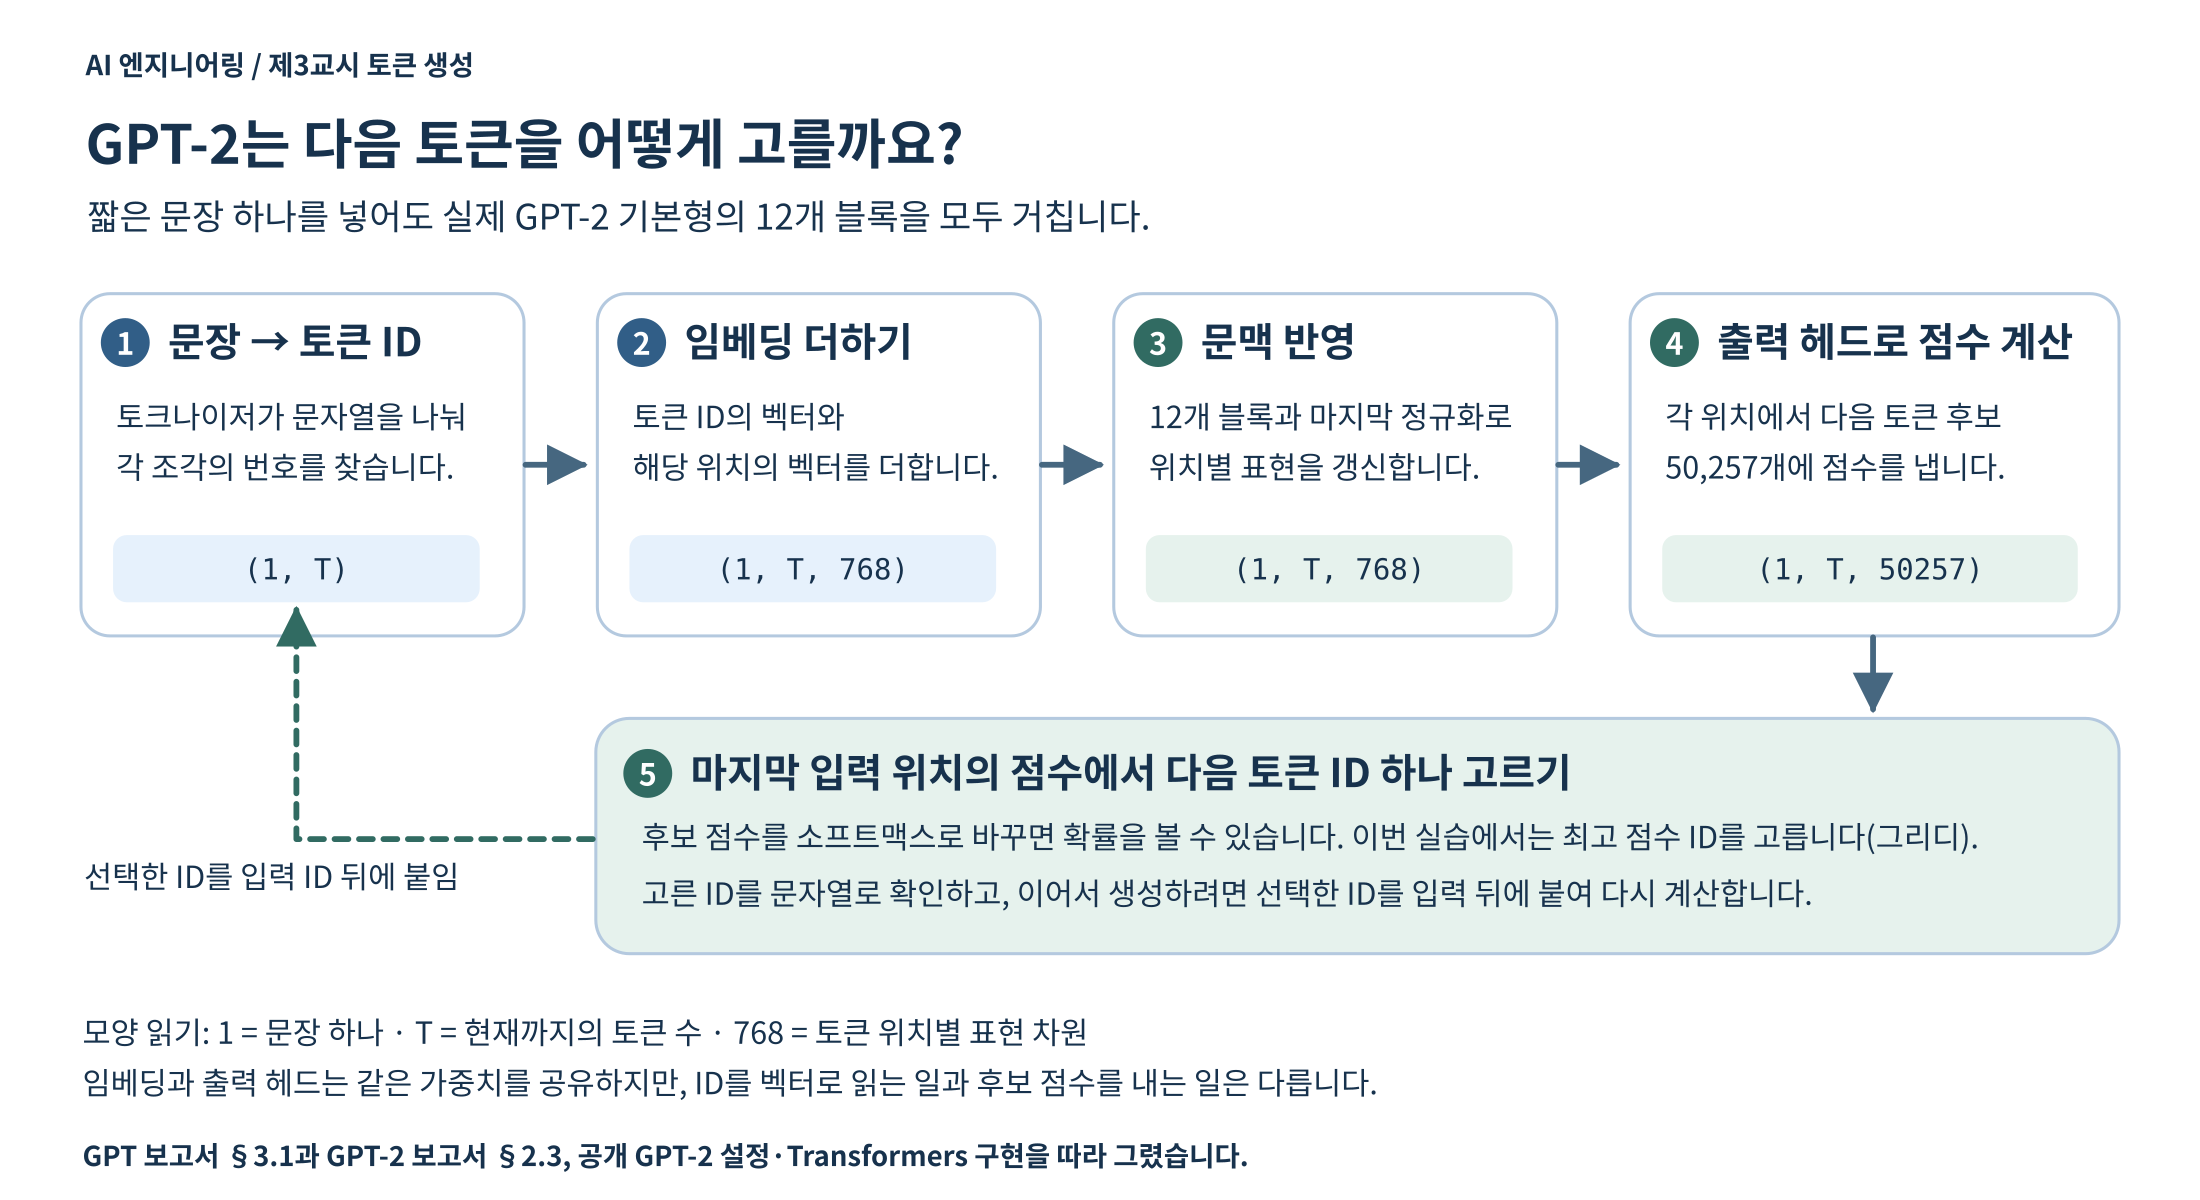

## 1. 실제 모델 준비하기

[실습 체크포인트의 고정 설정](https://huggingface.co/openai-community/gpt2/blob/607a30d783dfa663caf39e06633721c8d4cfcd7e/config.json)과 [학습 가중치](https://huggingface.co/openai-community/gpt2/blob/607a30d783dfa663caf39e06633721c8d4cfcd7e/model.safetensors)를 사용합니다.

`eval()`은 학습용 dropout을 끄고, `inference_mode()`는 기울기 기록을 생략합니다. 모델을 학습하거나 가중치를 변경하지 않습니다. 먼저 GPU 이름과 실제 블록 수를 확인합니다.

**경고 안내:** `IProgress not found`는 진행 표시 위젯에 관한 안내입니다. 모델 준비 셀이 `[PASS]`면 패키지를 추가 설치하지 않고 진행합니다.


### 개념 먼저: 생성은 한 번의 문장 검색이 아닙니다

언어 모델은 현재 입력에서 다음 토큰 후보 점수를 계산하고, 선택한 토큰을 입력에 붙여 다시 계산합니다. 이번에는 편의 생성 함수 대신 그 단계를 펼쳐 관찰합니다. 가중치를 새로 학습하는 과정과 이미 학습된 모델을 사용하는 추론을 구분합니다.

입력 문장과 완성 문장을 한 쌍으로 찾아오는 방식이라면 중간 선택을 관찰하기 어렵습니다. 여기서는 토큰화→표현 계산→후보 점수→ID 선택을 분리합니다. 매 단계에서 어디까지 계산했고 무엇은 아직 선택하지 않았는지 구별하면 이후 캐시가 줄이는 작업도 이해할 수 있습니다.


### 코드 설명: 생성 과정을 펼쳐 볼 모델 준비
이번 교시는 완성된 생성 함수 한 번으로 결과를 받는 대신, 토큰 ID에서 다음 토큰 선택까지의 단계를 분해해 관찰합니다. 앞 교시와 같은 학습된 GPT-2 및 토크나이저를 읽고, 블록 수와 표현 차원, 어휘 수가 예상과 같은지 검사합니다. **추론**은 이미 학습된 가중치를 사용해 출력하는 과정이며 이 실습에서는 가중치를 새로 학습하지 않습니다.

`eval()`은 학습 시에 쓰는 dropout의 무작위 변화를 끕니다. 다만 이것만으로 기울기 계산이 꺼지는 것은 아니므로 실제 계산에는 `inference_mode()`를 함께 사용합니다. 준비 `[PASS]`를 확인한 뒤, 이후 출력의 `T`와 768, 50257이 각각 무엇을 가리키는지 계속 구분해 읽으세요.


In [1]:
import sys, platform
import torch
import torch.nn.functional as F
import transformers
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

assert platform.system() == "Windows", "Windows 11 실습 환경을 사용하세요."
# CUDA 조건이 맞지 않으면 모델을 받기 전에 중단합니다.
assert torch.cuda.is_available(), "제1교시 CUDA 검사와 현재 Notebook 커널을 확인하세요."
# 장치 지정만 준비합니다. 텐서·모델의 실제 이동은 생성 옵션 또는 to(device)가 수행합니다.
device = torch.device("cuda:0")
# 저장소 이름과 아래 revision을 함께 고정하여 같은 파일을 사용합니다.
MODEL_ID = "openai-community/gpt2"
REVISION = "607a30d783dfa663caf39e06633721c8d4cfcd7e"
# 모델과 토크나이저에 같은 revision을 적용해 ID와 임베딩의 대응을 유지합니다.
tokenizer = GPT2TokenizerFast.from_pretrained(MODEL_ID, revision=REVISION)
# 출력 헤드까지 포함한 학습 가중치를 로드합니다. eval은 기울기 기록을 끄지는 않습니다.
model = GPT2LMHeadModel.from_pretrained(
    MODEL_ID, revision=REVISION, use_safetensors=True,
    # 관찰 가능한 eager 구현과 FP32 계산을 선택합니다. 모델 크기를 줄이지 않습니다.
    attn_implementation="eager", dtype=torch.float32,
).to(device).eval()
assert (len(model.transformer.h), model.config.n_head, model.config.n_embd,
        model.config.n_positions, model.config.vocab_size) == (12, 12, 768, 1024, 50257)
# 일부만 옮겨진 상태가 아닌지 모든 학습 파라미터의 장치를 확인합니다.
assert all(p.device.type == "cuda" for p in model.parameters())
# 현재 커널이 읽은 Python 정보입니다. 설치 명령을 실행한 다른 환경과 구분합니다.
print("Python:", sys.version.split()[0], "OS:", platform.system())
print("torch:", torch.__version__, "transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Blocks / heads / width / vocabulary:", 12, 12, 768, 50257)
print("[PASS] 실제 학습된 GPT-2 준비")

%USERPROFILE%\AI-Engineering\modern-llm-vlm-architecture\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1117 21:18:32.913000 33888 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1002.47it/s]


Python: 3.12.10 OS: Windows
torch: 2.9.1+cu126 transformers: 5.23.0
GPU: NVIDIA GeForce RTX 4090
Blocks / heads / width / vocabulary: 12 12 768 50257
[PASS] 실제 학습된 GPT-2 준비


### 출력 설명: 실행 기록과 확인 범위

- NVIDIA GeForce RTX 4090에 GPT-2를 불러왔으며, 구조 출력의 네 수는 차례대로 **블록 수 12, 헤드 수 12, 표현 폭 768, 어휘 크기 50,257**입니다. 이들은 생성 결과가 아니라 로드한 모델의 구조를 설명합니다.
- PASS에 도달하기 전에 설정값과 전체 파라미터의 CUDA 배치를 검사했습니다. 따라서 이 기록은 단순한 GPU 인식이 아니라 실제 가중치 준비까지 마친 상태입니다. 아직 문장을 입력하지 않았으므로 생성 품질은 판단할 수 없습니다.


## 2. 문장을 토큰 ID로 바꾸기
토큰은 단어와 항상 같지 않습니다. 단어 일부, 공백을 포함한 조각, 문장부호도 토큰이 될 수 있습니다. ID는 어휘 목록의 번호이지 의미의 크기를 나타내는 숫자가 아닙니다.

`repr()`은 공백을 눈으로 구분하기 위해 문자열의 따옴표를 함께 보여 줍니다. 토크나이저 내부 표기의 `Ġ`는 이 토크나이저의 공백 표현이며 실제 출력에 그 문자를 쓰라는 뜻이 아닙니다.
### GPT-2는 어떻게 문장을 조각내나요? Byte-level BPE

**Byte-level BPE(Byte Pair Encoding)**는 문장의 의미나 품사를 분석해 나누는 형태소 분석기가 아닙니다. 자주 함께 나타나는 이웃 조각을 합치는 규칙을 데이터에서 학습한 토크나이저입니다. 다음 순서로 이해하세요.

1. **먼저 큰 경계를 나눕니다(사전 분할).** GPT-2는 정규식으로 문자·숫자·문장부호 등의 구간을 구분합니다. BPE 병합은 이 사전 분할 경계를 넘지 않습니다. 단, **공백은 예외적으로 뒤 단어 등에 함께 붙을 수 있어** `' students'` 같은 조각을 허용합니다. 단순히 모든 공백을 지우거나 공백마다 잘라 버리는 방식이 아닙니다.
2. **각 구간을 UTF-8 바이트로 바꿉니다.** 기본 재료는 가능한 **256가지 바이트 값**입니다. 모든 유니코드 문자는 UTF-8 바이트열로 표현할 수 있으므로, 처음 보는 글자도 이 기본 재료로 표현할 수 있습니다. 이는 최종 어휘가 256개라는 뜻이 아닙니다. 이 GPT-2의 최종 어휘는 병합으로 만든 조각과 특수 토큰을 포함해 **50,257개**입니다.
3. **토크나이저 학습 때 병합 규칙을 만듭니다.** 말뭉치에서 자주 이웃하는 조각 쌍을 합치는 과정을 반복해 병합 목록과 그 순서를 배웁니다. 이는 GPT-2 신경망이 다음 토큰을 예측하도록 가중치를 학습하는 일과 구분됩니다.
4. **지금 입력을 처리할 때는 저장된 규칙을 적용합니다.** 입력 문장 안에서 빈도를 새로 세어 규칙을 다시 학습하지 않습니다. 현재 합칠 수 있는 이웃 쌍 중 **학습된 병합 우선순위**를 따라 합친 뒤, 최종 조각을 어휘의 ID로 바꿉니다. 이 실습은 공개된 토크나이저를 그대로 불러옵니다.

**왜 문자 단위 대신 바이트에서 출발할까요?** 다양한 문자를 모두 기본 어휘에 따로 등록할 필요 없이 256가지 바이트로 표현 범위를 확보하고, 자주 나타나는 바이트열은 병합해 길이를 줄일 수 있기 때문입니다. 표현할 수 있다는 사실이 모든 언어를 같은 수의 토큰으로 효율적으로 처리하거나 똑같이 잘 이해한다는 뜻은 아닙니다. 한글 한 글자도 여러 UTF-8 바이트로 이루어지며, **한 글자가 여러 토큰으로 나뉠 수 있습니다.**

### 실제 저장된 출력 설명: `Ġstudents` → ID `2444` → `' students'`

다음 실습 셀의 실제 출력에서 위치 1을 찾아보세요.

| 관찰 항목 | 실제 출력 | 뜻 |
|---|---|---|
| 내부 토큰 표시 | `'Ġstudents'` | 공백 바이트를 눈에 보이는 문자 `Ġ`로 표시한 조각입니다. |
| 토큰 ID | `2444` | 이 조각에 대응하는 어휘 번호입니다. 뜻의 크기나 순위가 아닙니다. |
| 디코딩한 조각 | `' students'` | 앞 공백과 `students`가 함께 들어 있습니다. 따옴표는 `repr()`의 표시입니다. |

단어 앞 공백의 유무가 토큰화를 바꿀 수 있으므로 `students`와 `' students'`를 무조건 같은 토큰이라고 생각하지 마세요. 이 출력만 보고 모든 영어 단어가 한 토큰이라고 일반화해서도 안 됩니다.

**복원은 전체 ID 배열로 확인합니다.** 아래 코드는 개별 토큰의 디코딩을 관찰용으로 출력하지만, 문장 복원 검사는 전체 ID 배열을 한 번에 디코딩합니다. 특히 한글처럼 한 문자의 바이트가 여러 토큰에 걸칠 때 각 ID를 따로 디코딩하면 완전한 문자가 되지 않아 `�` 같은 대체 문자가 보일 수 있습니다. 개별 결과를 이어 붙이는 대신 **전체 ID열 → 바이트열 복원 → UTF-8 문자열**로 이해하세요. 이 영어 예제의 전체 ID는 `[464, 2444, 2193, 9552, 1909, 13]`이며 원문 `The students learn AI today.`로 복원됩니다.

**확인 질문:** `Ġstudents`의 `Ġ`는 원문에 있던 장식 문자일까요, 공백의 내부 표시일까요? 한글 한 글자가 여러 토큰이어도 전체 배열을 디코딩하면 원문을 복원할 수 있는 이유는 무엇일까요?

바이트 수준의 입력 표현은 [GPT-2 보고서 §2.2](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)에서 설명합니다. 사전 분할과 병합 순위, 전체 바이트열을 문자열로 복원하는 과정은 [OpenAI GPT-2의 원본 encoder 구현](https://github.com/openai/gpt-2/blob/master/src/encoder.py)에서 확인할 수 있습니다. 이 설명은 기존 저장 출력을 해설하며 새 실행 결과를 추가한 것이 아닙니다.


### 개념 먼저: 토큰은 단어와 항상 일치하지 않습니다

토크나이저는 문장을 모델이 다룰 수 있는 조각과 번호로 바꿉니다. 한 단어가 여러 조각이 되거나 공백을 포함한 조각 하나가 될 수 있습니다. 따라서 문자 수·단어 수·토큰 수를 같은 것으로 가정하지 않고 실제 표를 읽습니다.

예를 들어 이번 출력에서 ` students`는 앞 공백을 포함한 조각이고 마침표는 따로 분리됩니다. 이는 해당 문장과 어휘 규칙에 대한 관찰이지 모든 단어의 분할 규칙이 아닙니다. 아래에서는 위치·ID·내부 표기·복원 조각을 나란히 보고, 전체 ID를 복원하여 원문이 유지되는지도 확인합니다.


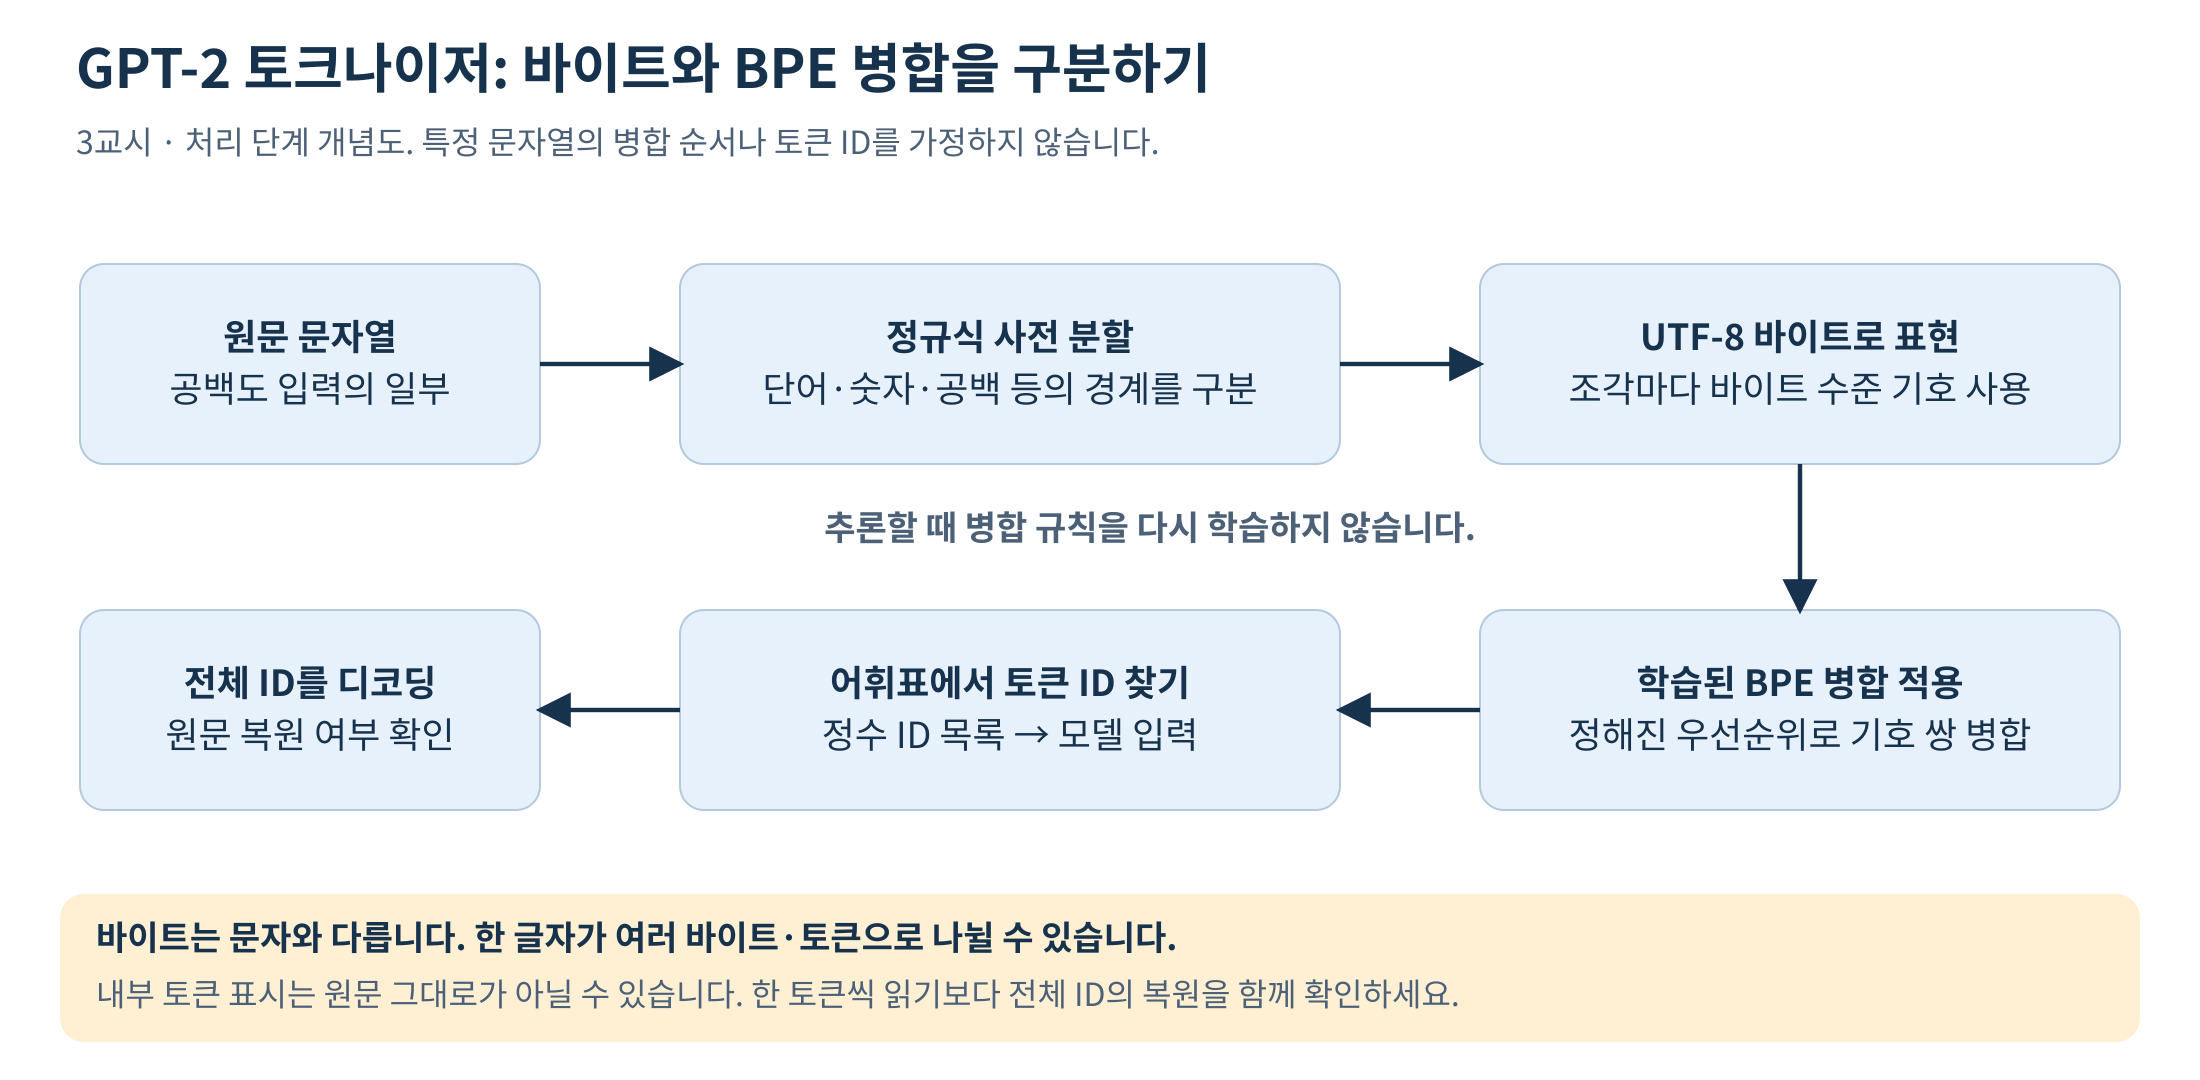

**그림 설명:** 일반적인 처리 단계의 개념도이며 병합 결과를 만든 예시 출력은 아닙니다. 실제 토큰과 ID는 이 노트북의 저장된 표를 읽으세요.


### 코드 설명: 토큰 표를 해석하는 순서
표의 `position`은 문장 안의 순서, `ID`는 어휘 목록의 번호입니다. 같은 토큰은 위치가 달라도 같은 ID를 가질 수 있습니다. `internal token`은 토크나이저 내부의 표시이고 `decoded piece`는 그 ID를 문자로 복원한 결과입니다. 아래 BPE 설명과 연결하여, 공백 표시를 포함한 내부 문자열을 원문 문자 그대로라고 오해하지 마세요.

`add_special_tokens=False`는 이 실습에서 별도 특수 토큰 자동 추가를 하지 않겠다는 설정입니다. `repr`은 공백을 식별하기 쉽게 보여줍니다. 성공 판단은 각 조각이 익숙한 단어인지가 아니라, 전체 ID를 함께 복원했을 때 원문과 같은지입니다. 특히 다른 언어를 넣을 때 개별 토큰 복원만으로 원문이 손상되었다고 단정하지 않습니다.


In [2]:
prompt = "The students learn AI today."
# 자동 특수 토큰 추가를 끄고 입력 문장 자체의 토큰 분할을 관찰합니다.
encoded = tokenizer(prompt, return_tensors="pt", add_special_tokens=False)
input_ids = encoded["input_ids"].to(device)
attention_mask = encoded["attention_mask"].to(device)
# 두 번째 축은 입력 토큰 수입니다. 문자 수나 단어 수와 항상 같지는 않습니다.
T = input_ids.shape[1]
assert input_ids.shape[0] == 1 and 0 < T < model.config.n_positions
print("Prompt:", repr(prompt))
print("IDs:", input_ids[0].tolist())
print("position | ID | internal token | decoded piece")
# 위치는 입력 순서이고 ID는 어휘 주소입니다. 개별 디코딩 조각의 앞 공백도 확인합니다.
for position, token_id in enumerate(input_ids[0].tolist()):
    print(position, token_id, repr(tokenizer.convert_ids_to_tokens(token_id)),
          repr(tokenizer.decode([token_id], clean_up_tokenization_spaces=False)))
# 전체 토큰 ID를 합쳐 복원해야 원문의 공백·문장부호까지 같은지 검사할 수 있습니다.
assert tokenizer.decode(input_ids[0].tolist(), clean_up_tokenization_spaces=False) == prompt
print("input_ids shape:", tuple(input_ids.shape))
print("[PASS] 실제 토큰화와 문장 복원")

Prompt: 'The students learn AI today.'
IDs: [464, 2444, 2193, 9552, 1909, 13]
position | ID | internal token | decoded piece
0 464 'The' 'The'
1 2444 'Ġstudents' ' students'
2 2193 'Ġlearn' ' learn'
3 9552 'ĠAI' ' AI'
4 1909 'Ġtoday' ' today'
5 13 '.' '.'
input_ids shape: (1, 6)
[PASS] 실제 토큰화와 문장 복원


### 출력 설명: 실행 기록과 확인 범위

- 각 행은 입력의 한 위치를 가리킵니다. `position`은 0부터 시작하는 순서이고 `ID`는 어휘 표의 주소이므로 둘을 같은 번호로 읽으면 안 됩니다.
- `Ġstudents`의 복원 조각은 앞 공백을 포함한 ` students`입니다. 마침표도 별도 위치를 차지하여 입력 모양이 `(1, 6)`, 즉 문장 1개와 토큰 6개가 되었습니다.
- PASS는 ID 전체를 다시 디코딩했을 때 공백과 문장부호까지 원문과 같았다는 뜻입니다. 이 예시가 6개로 분할되었다고 모든 영어 단어가 항상 한 토큰인 것은 아닙니다.


## 3. ID에서 768차원 표현으로 바꾸기
토큰 임베딩은 ID에 해당하는 **학습된 768개 숫자의 행**을 찾는 작업입니다. 위치 임베딩은 문장 안의 0, 1, 2… 위치에 해당하는 행을 찾습니다. GPT-2는 이 둘을 더합니다. 원래 Transformer 논문의 사인·코사인 위치 표현을 여기서 대신 계산하지 않습니다.

### 위치 벡터는 어디에서 오나요?

두 모델 모두 **토큰 벡터에 위치 벡터를 더합니다.** 차이는 위치 벡터를 만드는 방법입니다.

| 비교 | 원래 Transformer의 기본 방식 | GPT-2 기본형 |
|---|---|---|
| 위치 벡터를 얻는 법 | 위치 번호를 사인·코사인 공식에 넣어 계산합니다. | 위치 번호로 학습된 표 `wpe`의 행을 꺼냅니다. |
| 학습되는 값인가요? | 위치 벡터의 공식은 고정되어 있습니다. | 위치별 벡터도 다음 토큰을 예측하는 학습 과정에서 다른 가중치와 함께 조정됩니다. |
| 학습 때보다 긴 입력은요? | 공식은 더 큰 위치 번호에도 적용할 수 있지만, 그 입력에서 모델이 잘 동작한다는 보장은 아닙니다. | 이 체크포인트의 표는 1,024행 × 768열입니다. 위치 ID는 0~1023이며, 그 밖의 위치는 이 표에서 바로 꺼낼 수 없습니다. |

학습형은 **각 위치를 어떤 벡터로 표현할지 데이터에서 배울 여지**를 줍니다. 이것이 GPT-2에서 성능이 더 좋았다는 뜻은 아닙니다. [GPT-1 보고서 §4.1](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf)은 이미 학습형을 사용했다고 밝히지만 성능이 더 좋아 선택했다고 설명하지는 않습니다. [Transformer 원 논문 §3.5](https://arxiv.org/html/1706.03762#S3.SS5)에서는 두 방식의 번역 결과가 거의 같았으며, 학습 때보다 긴 입력에도 적용할 가능성을 고려해 사인·코사인 방식을 택했습니다.

**실행 전에 생각해 보세요.** 같은 토큰 ID가 두 번째 자리와 다섯 번째 자리에 있다면 무엇이 달라질까요? 토큰 임베딩은 같은 행을 읽지만, 위치 임베딩은 `wpe`의 위치 ID 1과 4, 즉 서로 다른 행을 읽습니다. 다음 실습의 `wpe(position_ids)`는 이 행을 **꺼내는 연산**이며, 사인·코사인 계산이 아닙니다.

shape `(1, T, 768)`은 문장 1개, 토큰 T개, 위치마다 숫자 768개라는 뜻입니다. 같은 위치의 숫자를 더하므로 768차원 그대로입니다. 다음 셀에서 실제 첫 블록 입력과도 비교합니다.

### 개념 먼저: 번호와 표현 벡터의 차이

토큰 ID는 어휘표의 행을 찾는 번호이고 임베딩은 그 행에 저장된 학습 벡터입니다. 같은 토큰이 다른 위치에 나오면 토큰 임베딩은 같지만 위치 임베딩은 달라집니다. GPT-2는 두 벡터를 더해 내용과 순서를 함께 입력합니다.

ID 100이 ID 50보다 의미가 두 배 크다는 해석은 성립하지 않습니다. ID는 조회 주소일 뿐이고, 계산에 쓰는 내용은 그 주소에서 꺼낸 실수 벡터입니다. 위치 벡터를 더해도 두 표현을 이어 붙이는 것이 아니므로 폭은 768 그대로입니다. 아래에서는 조회와 덧셈의 모양을 먼저 확인합니다.


### 코드 설명: ID를 벡터로 바꾸고 위치 정보 더하기
`wte`는 토큰 ID에 대응하는 학습된 임베딩을, `wpe`는 위치 번호에 대응하는 학습된 임베딩을 읽습니다. **임베딩**은 정수 번호 자체를 계산하는 대신 그 항목을 수치 벡터로 표현한 것입니다. `position_ids`는 토큰 ID와 별개로 0부터 시작하는 위치 번호입니다. GPT-2는 두 벡터를 더하여 첫 블록의 입력을 만듭니다.

두 텐서와 합의 크기가 모두 `(1, T, 768)`인지 확인하세요. 더하기는 같은 위치와 같은 성분끼리 이루어지므로 폭이 두 배가 되지 않습니다. 첫 8개 숫자는 계산을 관찰하는 예시이지, 개별 성분에 사람이 붙일 수 있는 고정 의미는 아닙니다. 다음 셀에서는 이 합이 실제 첫 블록 입력과 일치하는지 확인합니다.


In [3]:
# 토큰 ID와 별개인 위치 번호를 만들고 문장 축을 추가합니다.
position_ids = torch.arange(T, device=device).unsqueeze(0)
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    token_embeddings = model.transformer.wte(input_ids)
    # 위치 번호로 학습된 표의 행을 조회합니다. 토큰 ID로 조회하는 wte와 별개입니다.
    position_embeddings = model.transformer.wpe(position_ids)
    # 같은 위치·성분끼리 더하므로 표현 폭 768은 늘어나지 않습니다.
    combined_embeddings = token_embeddings + position_embeddings
assert token_embeddings.shape == position_embeddings.shape == combined_embeddings.shape == (1, T, 768)
print("token embeddings:", tuple(token_embeddings.shape))
print("position embeddings:", tuple(position_embeddings.shape))
print("sum:", tuple(combined_embeddings.shape))
print("first position, first 8 numbers:", combined_embeddings[0, 0, :8].tolist())
print("[PASS] 실제 토큰·학습된 위치 임베딩 합")

token embeddings: (1, 6, 768)
position embeddings: (1, 6, 768)
sum: (1, 6, 768)
first position, first 8 numbers: [-0.08744361251592636, -0.21771633625030518, 0.06849727779626846, -0.05073772370815277, -0.049695029854774475, -0.16734999418258667, -0.1802556961774826, -0.19777514040470123]
[PASS] 실제 토큰·학습된 위치 임베딩 합


### 출력 설명: 실행 기록과 확인 범위

- 세 모양이 모두 `(1, 6, 768)`인 이유는 토큰 표현과 위치 표현을 같은 위치·같은 성분끼리 **더했기 때문**입니다. 이어 붙였다면 폭이 늘겠지만 여기서는 768이 그대로입니다.
- 마지막 숫자 목록은 첫 위치 `The`의 결합 표현 중 앞 8개 성분만 보여 줍니다. 음수가 있어도 정상이며 확률·토큰 ID·8개 단어가 아닙니다. 전체 표현은 위치당 768개 실수입니다.
- PASS는 두 임베딩 표에서 조회하고 더한 세 텐서의 모양을 확인합니다. 합이 실제 첫 블록 입력으로 쓰였는지는 다음 셀의 hook 비교에서 확인합니다.


## 4. 12개 블록, 마지막 정규화, LM Head 따라가기
블록은 앞 문맥을 참고해 각 위치의 표현을 바꿉니다. 블록을 12번 통과해도 위치별 폭은 768입니다. GPT-2는 마지막에 `ln_f` 정규화도 적용합니다. **LM Head**는 그 최종 표현을 어휘 50,257개 각각의 점수(logit)로 바꿉니다. logit은 아직 확률이 아닙니다.

이번 모델은 입력 토큰 임베딩과 출력 LM Head가 같은 가중치를 공유합니다. 입력에서는 행을 찾아오고, 출력에서는 최종 표현과 각 행의 내적을 계산합니다. 같은 행을 사용하지만 역할은 다릅니다.

아래 hook은 실제 forward의 중간 값을 잠시 관찰하는 장치입니다. 계산을 대체하지 않으며, 끝나면 반드시 제거합니다. 첫 블록 입력을 임베딩 합과 비교하고, 최종 정규화 출력을 직접 LM Head에 넣은 점수를 모델 전체 출력과 비교합니다.
**2교시와 연결:** 블록 안의 `ln_1`·`ln_2`는 어텐션과 MLP 앞에 있습니다. 여기서 보는 `ln_f`는 12개 블록을 모두 통과한 뒤 LM Head 직전에 적용하는 별도 정규화입니다.


### 개념 먼저: 중간 표현과 어휘 점수를 연결하기

블록은 각 위치의 표현을 문맥에 맞게 갱신합니다. 마지막 정규화 뒤에도 표현 폭은 유지되지만 의미를 담는 값은 처음과 달라집니다. LM Head는 이 표현을 어휘별 점수로 바꾸므로 표현 차원 축이 후보 어휘 축으로 바뀝니다.

표현의 768개 성분에 각각 단어 이름이 하나씩 대응하는 것은 아닙니다. 출력층이 이 성분들을 학습된 가중치로 조합하여 후보마다 점수 하나를 만듭니다. 아래에서는 실제 실행 지점에 관찰 함수를 달고, 최종 표현에 출력층을 따로 적용해도 전체 모델 점수와 같은지 확인합니다.


### 코드 설명: 실제 실행 경로를 관찰하는 hook
**hook**은 모델의 특정 지점이 실행될 때 값을 관찰하는 장치입니다. 여기서는 첫 블록 입력, 마지막 정규화 출력, 각 블록의 방문 순서를 기록합니다. 모델 구조를 축소하거나 가중치를 바꾸지 않고 실제 forward의 중간 결과를 얻습니다. `finally`에서 hook을 제거하므로 셀을 다시 실행해도 관찰 장치가 중복 누적되지 않습니다.

방문 순서 0~11, 최종 표현 `(1, T, 768)`, logits `(1, T, 50257)`을 연결해서 읽으세요. **가중치 공유**는 입력 임베딩과 출력 LM Head가 같은 행렬을 쓰는 것입니다. 메모리 주소와 재계산 결과를 모두 대조합니다. `[PASS]`는 관찰한 경로와 재구성한 출력의 일치를 뜻하며, hook 자체가 새로운 학습 단계는 아닙니다.

**수치 비교 기준: 임베딩과 출력층의 서로 다른 비교 기준**

`allclose(a, b)`는 두 번째 인자 `b`를 기준으로 모든 성분에서 다음 조건을 검사합니다: $|a-b| \leq \mathrm{atol} + \mathrm{rtol}\,|b|$. `atol`은 절대 허용오차, `rtol`은 기준값 크기에 비례한 상대 허용오차입니다.

첫 블록 입력의 기준은 `combined_embeddings`이며 `atol=rtol=1e-6`입니다. 기준 성분의 절댓값이 0.1이라면 허용 차이는 0.0000011입니다(계산 설명용 예). 두 출력층 재구성의 기준은 모두 `direct.logits`이고 `atol=rtol=1e-5`입니다. 기준 점수의 절댓값이 10이면 0.00011까지 허용합니다(계산 설명용 예). 화면의 LM-head 최대 차이는 모든 성분을 요약한 수치이며, 모든 성분에 공통으로 적용하는 고정 임계값이 아닙니다.


In [4]:
# hook으로 복사할 실제 중간값을 이름별로 보관합니다.
observed = {}
block_order = []
# 순전파 직전 첫 입력을 복사하여 임베딩 합과 대조합니다. 반환값으로 입력을 바꾸지 않습니다.
def capture_first(module, args):
    observed["first_input"] = args[0].detach().clone()
# 최종 정규화가 끝난 표현을 복사합니다. 블록 출력과 최종 정규화 출력을 구분합니다.
def capture_final(module, args, output):
    observed["final_hidden"] = output.detach().clone()
# 블록 번호를 기억하는 함수를 만들어 순서대로 방문했는지 기록합니다.
def block_hook(index):
    def capture(module, args, output):
        block_order.append(index)
    return capture

# 등록 반환값은 해제용 handle입니다. 관찰 함수는 원래 출력을 바꾸지 않습니다.
handles = [model.transformer.h[0].register_forward_pre_hook(capture_first),
           model.transformer.ln_f.register_forward_hook(capture_final)]
# 첫 블록의 상세 관찰과 별개로 모든 블록의 방문을 기록합니다.
handles += [block.register_forward_hook(block_hook(i))
            for i, block in enumerate(model.transformer.h)]
try:
    # 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
    with torch.inference_mode():
        direct = model(input_ids, attention_mask=attention_mask, use_cache=False)
# 실행에 실패해도 hook을 제거하여 다음 실행 때 중복 관찰을 막습니다.
finally:
    for handle in handles:
        # 재실행 시 관찰 함수가 중복 호출되지 않도록 등록한 hook을 제거합니다.
        handle.remove()

# 블록 개수뿐 아니라 0부터 시작하는 실행 순서도 검사합니다.
assert block_order == list(range(12))
# eval 모드에서는 임베딩 뒤 dropout이 값을 변경하지 않습니다.
# 기준 b = combined_embeddings; 원소별 허용 차이 = 1e-06 + 1e-06 × |b|.
assert torch.allclose(observed["first_input"], combined_embeddings, atol=1e-6, rtol=1e-6)
# 최종 정규화를 거친 위치별 768차원 표현입니다. 아직 어휘별 점수가 아닙니다.
final_hidden = observed["final_hidden"]
assert final_hidden.shape == (1, T, 768)
# 모양 일치보다 강한 검사: 입력·출력 가중치가 같은 저장 공간을 공유하는지 봅니다.
assert model.lm_head.weight.data_ptr() == model.transformer.wte.weight.data_ptr()
assert model.lm_head.bias is None
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    head_logits = model.lm_head(final_hidden)
    # 공유 입력 임베딩 행렬을 출력 투영에 써서 전체 모델의 logits와 대조합니다.
    tied_logits = F.linear(final_hidden, model.transformer.wte.weight)
assert head_logits.shape == direct.logits.shape == (1, T, 50257)
# 기준 b = direct.logits; 원소별 허용 차이 = 1e-05 + 1e-05 × |b|.
assert torch.allclose(head_logits, direct.logits, atol=1e-5, rtol=1e-5)
# 기준 b = direct.logits; 원소별 허용 차이 = 1e-05 + 1e-05 × |b|.
assert torch.allclose(tied_logits, direct.logits, atol=1e-5, rtol=1e-5)
print("Visited blocks:", block_order)
print("final hidden:", tuple(final_hidden.shape))
print("logits:", tuple(direct.logits.shape))
print("Tied input/output weights:", True)
print("LM-head max difference:", (head_logits - direct.logits).abs().max().item())
print("[PASS] 실제 12블록·최종 정규화·공유 LM Head 일치")

Visited blocks: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
final hidden: (1, 6, 768)
logits: (1, 6, 50257)
Tied input/output weights: True
LM-head max difference: 0.0
[PASS] 실제 12블록·최종 정규화·공유 LM Head 일치


### 출력 설명: 실행 기록과 확인 범위

- 방문 목록이 0부터 11까지 순서대로 기록되어 전체 12개 블록을 거쳤습니다. 최종 정규화 뒤의 `(1, 6, 768)`에서 LM Head를 지나 `(1, 6, 50257)`로 바뀐 것은 위치 수는 유지하고 표현 성분을 어휘별 점수로 바꾸었다는 뜻입니다.
- 공유 가중치의 `True`는 입력 임베딩과 출력층이 같은 저장 공간을 참조한다는 검사 결과입니다. 모양만 같다는 뜻보다 강한 확인입니다.
- LM Head를 따로 적용한 점수와 전체 모델 점수의 최대 차이는 0입니다. PASS는 첫 블록 입력의 임베딩 합 일치, 블록 방문 순서, 공유 가중치를 사용한 두 점수 재구성까지 검사했습니다. 다음 셀에서 이 점수 중 마지막 위치만 선택합니다.

**판정 기준 연결:** 이 셀의 비교는 `atol=1e-06, rtol=1e-06`, `atol=1e-05, rtol=1e-05`를 사용합니다. 위 **코드 설명의 수치 비교 기준**에서 각 비교의 두 번째 인자와 실제 허용 차이 계산을 확인하세요. 출력의 최대 절대 차이와 `atol`만 비교하는 방식이 아니라, 각 기준값에 따른 `atol + rtol × |기준값|`으로 판정합니다.


## 5. 마지막 위치 점수에서 다음 토큰 후보 보기
각 위치의 점수는 그 위치 **다음** 토큰의 후보 점수입니다. 프롬프트 전체 다음에 붙일 토큰은 마지막 위치의 `logits[0, -1]`에서 선택합니다. 길이가 T라고 해서 T번째 ID를 그대로 복사하는 것이 아닙니다.

softmax는 50,257개 점수를 모두 사용해 합이 1인 분포로 바꿉니다. 대개 1보다 작습니다. 아래 표는 전체 분포에서 상위 5개를 골라 보여 줄 뿐 다시 정규화하지 않습니다. 이는 top-k 샘플링을 수행하는 코드가 아닙니다. 확률은 이 모델의 다음 토큰 분포이며 문장이 사실일 확률이나 정답률이 아닙니다.

### 개념 먼저: 점수와 확률, 표시한 후보를 구분하기

logits는 정규화하지 않은 점수이고 softmax는 전체 후보를 합이 1인 확률로 바꿉니다. 화면에 상위 다섯 개만 보여도 다른 후보가 없어진 것은 아닙니다. 상위 후보의 합과 전체 확률 합을 나누어 읽어야 선택의 불확실성을 과장하지 않습니다.

이번 저장 결과에서 상위 다섯 후보의 합은 약 48.22%입니다. 화면에 보이지 않는 후보들이 나머지 약 51.78%를 가지고 있으므로, 다섯 후보가 전체 선택지를 대표한다고 단정할 수 없습니다. 아래 코드는 전체 어휘의 확률 합을 먼저 확인한 뒤 표시할 후보만 추립니다. 표시 범위를 줄이는 것과 확률을 다시 정규화하는 것은 다릅니다.

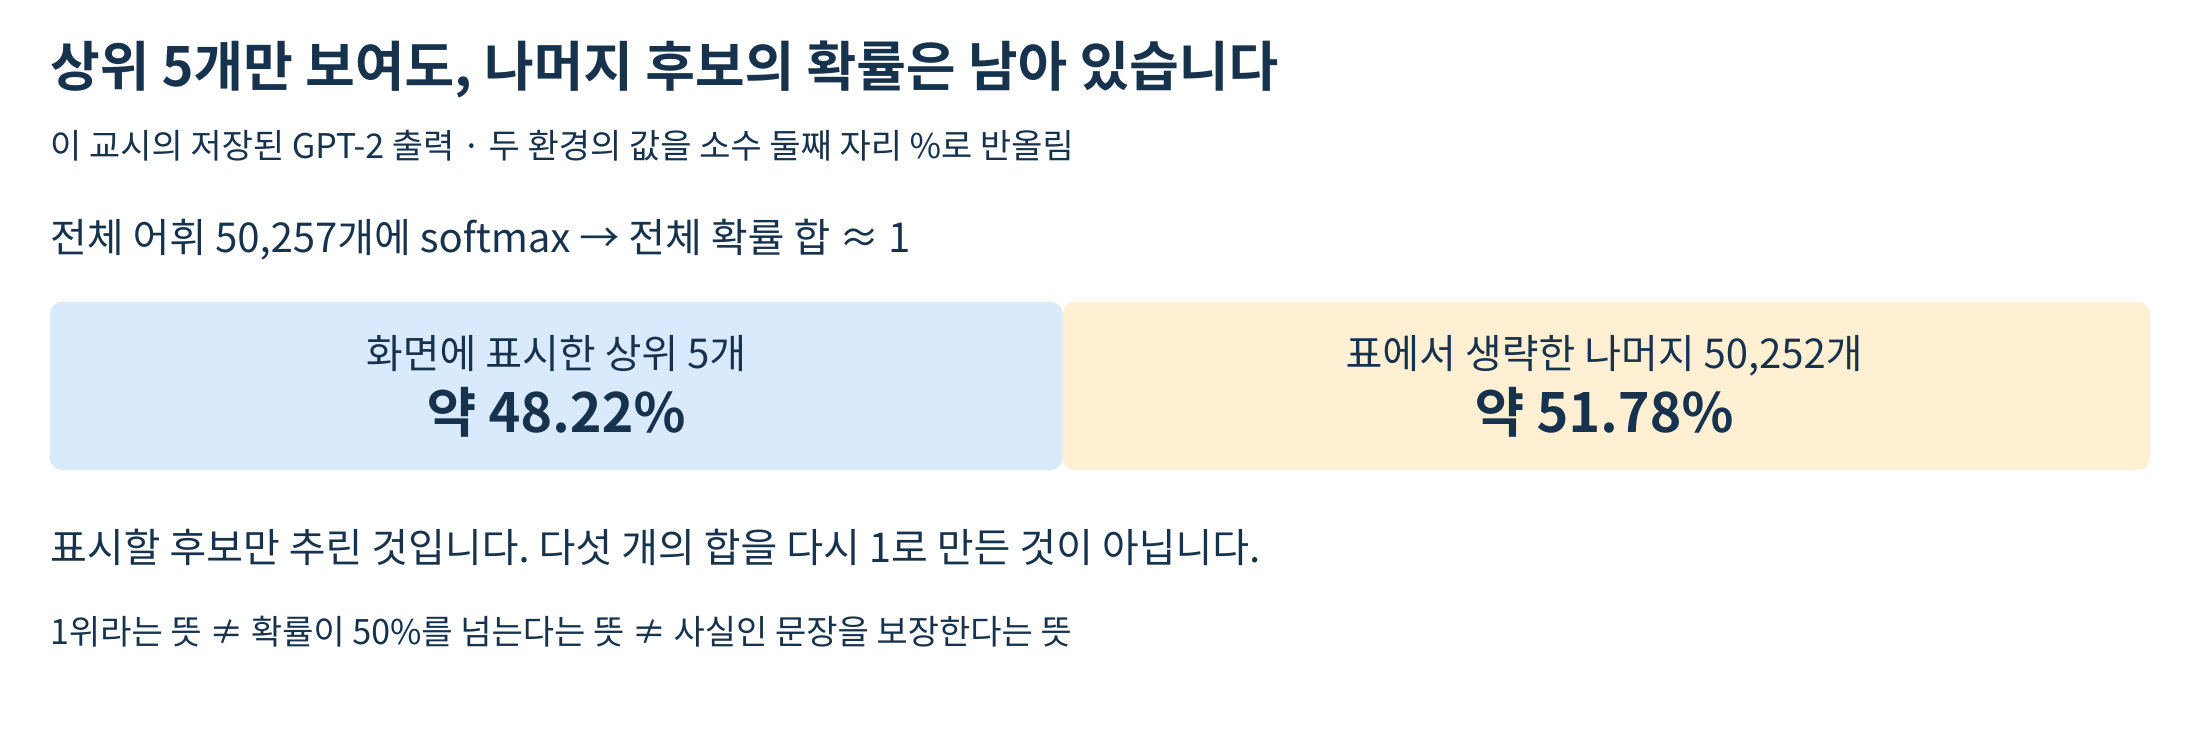

**그림 설명:** 파란 부분은 표시한 후보들의 확률 합, 주황 부분은 생략한 후보들의 합입니다. 색 영역의 폭은 반올림한 비율을 나타내며 후보의 개수 비율이 아닙니다.


### 코드 설명: 마지막 위치의 점수를 다음 토큰 확률로
다음 토큰을 고를 때는 모든 위치의 점수가 아니라 마지막 입력 위치의 logits를 사용합니다. `softmax`는 어휘 50257개 전체에 걸쳐 점수를 정규화한 확률 분포를 만듭니다. `topk`는 이 전체 분포에서 높은 후보 다섯 개만 골라 보여주는 표시용 단계입니다. 이 셀은 후보를 무작위로 뽑거나 생성하지 않습니다.

전체 확률 합은 약 1이고, 상위 다섯 개의 합은 일반적으로 1보다 작습니다. 나머지 확률이 다른 어휘에 남아 있기 때문입니다. 표의 확률은 ‘다섯 후보 안에서 다시 계산한 비율’이 아닙니다. 후보의 복원 문자열에서 앞 공백도 확인하세요. 확률이 높다는 것은 이 모델의 선택 경향이지 사실성이나 정답 여부의 보증은 아닙니다.

**수치 비교 기준: 확률 합의 실제 허용오차**

`allclose(a, b)`는 두 번째 인자 `b`를 기준으로 모든 성분에서 다음 조건을 검사합니다: $|a-b| \leq \mathrm{atol} + \mathrm{rtol}\,|b|$. `atol`은 절대 허용오차, `rtol`은 기준값 크기에 비례한 상대 허용오차입니다.

두 번째 인자는 기준 합 **1.0**입니다. 코드에는 `atol=1e-6`만 썼으므로 `rtol`은 PyTorch 기본값 **1e-5**가 적용됩니다. 실제 허용 차이는 `0.000001 + 0.00001 × 1 = 0.000011`입니다. `rtol=0`으로 검사하거나 소수점 여섯 자리의 정확한 일치를 요구하는 코드가 아닙니다.


In [5]:
# 마지막 위치의 어휘 점수만 고르면 문장·위치 축 없이 (50257,)이 남습니다.
last_logits = direct.logits[0, -1].float()
# 전체 어휘에 걸쳐 softmax를 적용합니다. 상위 후보만 따로 정규화하지 않습니다.
probabilities = torch.softmax(last_logits, dim=-1)
# 전체 어휘 확률은 유지하고 화면에 보여줄 상위 후보만 선택합니다.
top_probs, top_ids = torch.topk(probabilities, k=5)
assert last_logits.shape == probabilities.shape == (50257,)
# NaN·무한대·음수 확률이 섞이지 않았는지 검사합니다. 합이 1인지만 보는 것으로는 부족합니다.
assert torch.isfinite(probabilities).all() and (probabilities >= 0).all()
# 기준 b = torch.tensor(1.0, device=device); 원소별 허용 차이 = 1e-06 + 1e-05 × |b|. rtol은 기본값입니다.
assert torch.allclose(probabilities.sum(), torch.tensor(1.0, device=device), atol=1e-6)
assert torch.all(top_probs[:-1] >= top_probs[1:])
print("last-position logits:", tuple(last_logits.shape))
print("rank | ID | decoded piece | probability in full vocabulary")
# 같은 순위의 ID와 확률을 짝지어 표시합니다. 값은 상위 다섯 개 안이 아닌 전체 어휘 기준입니다.
for rank, (token_id, probability) in enumerate(zip(top_ids.tolist(), top_probs.tolist()), 1):
    print(rank, token_id, repr(tokenizer.decode([token_id], clean_up_tokenization_spaces=False)), f"{probability:.8f}")
print("Full probability sum:", probabilities.sum().item())
print("Top-5 probability mass:", top_probs.sum().item())
print("[PASS] 전체 어휘 softmax와 정규화하지 않은 상위 5개")

last-position logits: (50257,)
rank | ID | decoded piece | probability in full vocabulary
1 1119 ' They' 0.16340733
2 198 '\n' 0.15214048
3 383 ' The' 0.06964649
4 632 ' It' 0.06617483
5 775 ' We' 0.03080422
Full probability sum: 1.0
Top-5 probability mass: 0.482173353433609
[PASS] 전체 어휘 softmax와 정규화하지 않은 상위 5개


### 출력 설명: 실행 기록과 확인 범위

- `(50257,)`은 마지막 입력 위치의 점수만 골라 문장 축과 위치 축을 없앤 결과입니다. 화면의 5개 행은 전체 어휘에 softmax를 적용한 뒤 확률이 높은 후보만 추린 것입니다.
- 첫 후보는 앞 공백을 포함한 ` They`이고 확률은 약 16.3407%입니다. 줄바꿈도 후보에 포함되어 있습니다. 이러한 값은 이 입력 뒤에 각 토큰이 올 모델의 예측 확률이며, 문장의 사실성이나 정답 확률을 뜻하지 않습니다.
- 상위 5개를 합쳐도 약 48.22%뿐입니다. 나머지 약 51.78%는 화면에 생략한 후보들에 배분되어 있습니다. 전체 합은 이 기록에서 1입니다. PASS는 확률의 유한성·음수 없음·전체 합·내림차순을 검사하며, 상위 5개만 다시 합이 1이 되게 만들지 않았습니다.

**판정 기준 연결:** 이 셀의 비교는 `atol=1e-06, rtol=1e-05` (rtol 기본값)를 사용합니다. 위 **코드 설명의 수치 비교 기준**에서 각 비교의 두 번째 인자와 실제 허용 차이 계산을 확인하세요. 출력의 최대 절대 차이와 `atol`만 비교하는 방식이 아니라, 각 기준값에 따른 `atol + rtol × |기준값|`으로 판정합니다.


## 6. 가장 큰 점수의 토큰 하나 붙이기
Greedy(탐욕적 선택)는 현재 가장 높은 점수의 토큰을 하나 고릅니다. softmax는 점수 순서를 유지하므로 점수 argmax와 확률 argmax가 같습니다. 무작위 추첨이 아닙니다. 가장 높은 첫 후보를 고른다고 전체 문장이 최선이거나 사실이라는 보장은 없습니다.

`repr()`과 전체 복원 문장을 함께 봅니다. 토큰 ID를 입력 오른쪽에 붙여야 다음 계산에 새 문맥이 반영됩니다.

**이 예제의 확인값:** 첫 선택은 ID `1119`, 디코딩한 조각은 ` They`입니다. `They` 앞의 공백도 토큰에 들어 있어서 앞 문장에 그대로 이어집니다.


### 개념 먼저: 선택 규칙은 모델 계산 다음에 적용합니다

greedy는 현재 점수가 가장 큰 후보 하나를 고르는 규칙입니다. 모델이 점수를 계산하는 일과 사람이 정한 규칙으로 고르는 일은 구분됩니다. 현재 최고 후보가 전체 문장 품질의 최선을 보장하는 것은 아닙니다.

같은 logits에도 최댓값을 고르거나 확률에 따라 뽑는 등 서로 다른 선택 규칙을 적용할 수 있습니다. 이번에는 비교가 쉬운 greedy를 사용합니다. softmax는 점수의 순서를 유지하므로 최댓값 ID를 고르는 데 확률 변환이 필수는 아닙니다. 아래에서는 선택한 ID 하나를 입력에 붙이는 단계까지만 수행합니다.


### 코드 설명: 후보를 실제 다음 입력에 추가하기
**greedy 선택**은 현재 점수가 가장 높은 토큰 하나를 고르는 방법입니다. softmax 전후로 순위가 유지되므로 logits의 `argmax`, 확률의 `argmax`, 앞 셀의 1위 ID가 같은지 검사합니다. 무작위 샘플링과 달리 여기에는 추첨 과정이 없습니다. 다만 당장의 최고 점수를 고르는 것이 전체 문장의 최적 결과를 보장하지는 않습니다.

선택한 ID를 `(1, 1)` 텐서로 만들고 입력의 길이 축에 붙입니다. 결과 크기가 `(1, T+1)`이며 기존 앞부분이 그대로인지 확인하세요. 이 셀은 한 토큰을 선택해 추가했을 뿐, 추가된 입력을 다시 모델에 통과시키지는 않습니다. 다음 토큰의 다음 토큰을 얻으려면 이어지는 셀처럼 재계산이 필요합니다.


In [6]:
# 최고 점수의 위치가 토큰 ID입니다. item으로 Python 정수 하나를 꺼냅니다.
greedy_id = last_logits.argmax().item()
assert greedy_id == probabilities.argmax().item() == top_ids[0].item()
# 기존 입력과 자료형·장치를 맞춘 (문장 1개, 토큰 1개) 텐서를 만듭니다.
one_token = torch.tensor([[greedy_id]], dtype=input_ids.dtype, device=device)
# 길이 축에 붙입니다. 이 줄은 새 토큰을 모델에 다시 처리하는 단계는 아닙니다.
extended_ids = torch.cat([input_ids, one_token], dim=1)
assert extended_ids.shape == (1, T + 1)
assert torch.equal(extended_ids[:, :T], input_ids)
print("Greedy next ID:", greedy_id)
print("Decoded piece:", repr(tokenizer.decode([greedy_id], clean_up_tokenization_spaces=False)))
print("Extended text:", repr(tokenizer.decode(extended_ids[0].tolist(), clean_up_tokenization_spaces=False)))
print("[PASS] 다음 토큰 하나 선택·입력에 추가")

Greedy next ID: 1119
Decoded piece: ' They'
Extended text: 'The students learn AI today. They'
[PASS] 다음 토큰 하나 선택·입력에 추가


### 출력 설명: 실행 기록과 확인 범위

- 선택된 ID 1119는 이 토크나이저에서 앞 공백을 포함한 ` They`입니다. 가장 큰 점수의 위치를 고르는 greedy 선택이므로 앞 셀의 1위 후보와 일치합니다.
- 복원한 문장이 `They`까지 늘어난 것은 새 ID를 입력 뒤에 하나 붙였기 때문입니다. 이 셀은 여러 단어를 한 번에 생성한 것이 아니며, 붙인 토큰을 다시 모델에 통과시키는 반복은 다음 셀에서 수행합니다.
- PASS는 점수에서 고른 ID가 확률의 최상위 ID와 같고, 확장된 입력 길이가 정확히 한 칸 늘었음을 확인합니다.


## 7. 같은 과정을 최대 5번 반복하기
매번 ‘현재 전체 입력 → 마지막 위치 점수 → argmax → ID 추가’를 반복합니다. 모델은 한 번에 완성된 문장을 꺼내지 않습니다. 처음 프롬프트에서 다시 시작하므로 앞 셀의 토큰을 중복으로 붙이지 않습니다.

캐시는 이번에 사용하지 않습니다(`use_cache=False`). 각 단계에서 늘어난 입력 전체를 다시 계산하면 흐름을 이해하기 쉽습니다. 속도 비교용 코드는 아닙니다. 종료 토큰을 선택하면 중단하고, 그렇지 않으면 5개에서 멈춥니다. 마지막 결과는 모델이 만든 예시이며 정확성 평가 결과가 아닙니다.

**이 예제의 종료 이유:** `They learn how to use`에서 멈춘 것은 종료 토큰이 나왔기 때문이 아니라, 새 토큰을 5개까지만 만들도록 실습에서 제한했기 때문입니다.


### 개념 먼저: 새로 고른 토큰이 다음 계산의 문맥이 됩니다

한 토큰을 붙인 뒤에는 그 토큰까지 포함한 입력으로 다시 점수를 계산합니다. 반복하면서 모델이 참고하는 문맥도 길어집니다. 이 실습은 과정을 보이기 위해 매번 전체 입력을 재계산하며, 뒤의 KV 캐시 실습은 같은 계산의 재사용 가능 부분을 다룹니다.

처음 고른 조각이 ` They`라면 다음 계산에서는 원문 뒤의 이 조각까지 참고하여 그 뒤 후보를 예측합니다. 다섯 번 반복한다는 것은 다섯 문장을 만드는 것이 아니라 최대 다섯 토큰을 차례로 추가한다는 뜻입니다. 종료 토큰이 먼저 선택되면 중단하며, 문장이 자연스럽게 끝나기 전에 정한 단계 수가 소진될 수도 있습니다.


### 코드 설명: 자기회귀 생성의 반복을 눈으로 확인
**자기회귀 생성**은 지금까지의 입력으로 다음 토큰을 고르고, 그 토큰을 입력에 붙여 같은 과정을 반복하는 방식입니다. 이 셀은 원래 문장부터 다시 시작하여 최대 다섯 번 반복합니다. 각 줄의 ID, 복원 조각, 길이를 연결해 보면 한 번의 forward가 완성된 문장 전체를 출력하는 것이 아님을 확인할 수 있습니다.

`EOS`는 종료를 뜻하는 특수 토큰이며 선택되면 일찍 멈춥니다. 첫 선택이 앞 셀의 ID와 같고 최종 길이가 원래 길이와 생성 토큰 수의 합인지 검사합니다. 이해를 위해 캐시 없이 매번 전체 입력을 재계산하므로 효율적인 배포 방식은 아닙니다. 다음 캐시 실습에서는 이 반복에서 어떤 계산을 재사용할 수 있는지 살펴봅니다.


In [7]:
# 직전 셀의 확장 입력이 아니라 원래 문장에서 시작해 첫 선택을 대조합니다.
sequence = input_ids.clone()
# 원래 입력을 제외하고 이번 반복에서 고른 ID만 모읍니다.
generated_ids = []
for step in range(5):
    # 전체 길이는 원래 길이와 실제 생성한 토큰 수의 합이어야 합니다. EOS로 일찍 멈춰도 적용됩니다.
    assert sequence.shape[1] < model.config.n_positions
    # 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
    with torch.inference_mode():
        result = model(sequence, attention_mask=torch.ones_like(sequence), use_cache=False)
    # 문장 0의 마지막 위치에서 가장 높은 점수의 어휘 번호 하나를 선택합니다.
    next_id = result.logits[0, -1].argmax().item()
    generated_ids.append(next_id)
    # 이전 셀의 확장 문장이 아니라 원래 입력부터 반복을 다시 시작합니다.
    # 새 ID를 기존 입력과 같은 자료형·장치로 만들고 길이 축에 붙입니다.
    sequence = torch.cat([sequence, sequence.new_tensor([[next_id]])], dim=1)
    print("step", step + 1, "ID", next_id, "piece", repr(tokenizer.decode([next_id], clean_up_tokenization_spaces=False)), "length", sequence.shape[1])
    # 종료 토큰도 추가한 뒤 반복을 멈추므로 생성 ID 목록에 포함됩니다.
    if next_id == tokenizer.eos_token_id:
        print("EOS selected: stop")
        break
assert generated_ids[0] == greedy_id
# 전체 길이는 원래 길이와 실제 생성한 토큰 수의 합이어야 합니다. EOS로 일찍 멈춰도 적용됩니다.
assert sequence.shape[1] == T + len(generated_ids)
assert torch.equal(sequence[:, :T], input_ids)
print("Generated IDs:", generated_ids)
print("Final text:", repr(tokenizer.decode(sequence[0].tolist(), clean_up_tokenization_spaces=False)))
print("[PASS] 실제 GPT-2의 단계별 greedy 반복")
print("[PASS] Lesson 03 완료")

step 1 ID 1119 piece ' They' length 7
step 2 ID 2193 piece ' learn' length 8
step 3 ID 703 piece ' how' length 9
step 4 ID 284 piece ' to' length 10
step 5 ID 779 piece ' use' length 11
Generated IDs: [1119, 2193, 703, 284, 779]
Final text: 'The students learn AI today. They learn how to use'
[PASS] 실제 GPT-2의 단계별 greedy 반복
[PASS] Lesson 03 완료


### 출력 설명: 실행 기록과 확인 범위

- 길이가 7에서 11로 한 칸씩 증가한 것은 원래 6개 토큰 뒤에 매 단계 한 개씩 추가했기 때문입니다. 이 반복은 앞 셀의 확장 결과가 아니라 원래 문장에서 다시 시작하므로 `They`가 두 번 붙지 않습니다.
- 다섯 조각이 이어져 `They learn how to use`까지 나왔습니다. 종료 토큰을 만나지 않고 지정한 5단계를 모두 사용했으므로 문장이 미완성인 것은 검사 실패가 아닙니다.
- PASS는 첫 선택이 앞 셀과 같은지, 전체 길이가 추가한 토큰 수만큼 늘었는지, 원래 입력 부분이 보존되었는지를 검사합니다. 이번에는 캐시 없이 늘어난 입력 전체를 다시 계산했으며, 문장 품질·속도 비교나 정답 검증을 수행한 것은 아닙니다.


## 정리와 자기 점검
1. ID는 행 번호이고 임베딩은 학습된 숫자 벡터입니다.
2. GPT-2는 토큰 표현과 학습된 위치 표현을 더하고 12개 블록과 최종 정규화를 통과시킵니다.
3. LM Head는 768차원 표현을 어휘별 점수로 바꿉니다. 이 체크포인트는 입력·출력 가중치를 공유합니다.
4. 마지막 위치 점수에서 다음 토큰 하나를 선택하고 붙인 뒤 다시 계산합니다.

다시 검증하려면 커널을 재시작하고 처음부터 전체 실행하세요. 오류가 나오면 해당 셀의 출력과 커널 정보를 보존하세요. 실행하지 않은 셀을 PASS로 간주하지 않습니다.


### 자기 점검 질문

1. 다음 토큰을 고를 때 마지막 위치의 logits를 읽는 이유는 무엇인가요?

   **핵심 답과 이유:** 마지막 입력 위치의 표현은 인과 마스크 안에서 현재까지 주어진 전체 문맥을 참고하며, 그 위치의 logits가 바로 다음 토큰을 예측하기 때문입니다. 앞 위치의 logits는 해당 위치까지만 본 문맥 뒤의 토큰을 예측합니다.

2. 토큰 선택과 선택한 토큰을 다시 입력하여 계산하는 단계는 어떻게 다른가요?

   **핵심 답과 이유:** 선택은 이미 계산된 점수에서 토큰 ID 하나를 정하는 단계입니다. 그 ID를 입력 뒤에 붙여 다시 모델에 통과시켜야 새 문맥의 점수가 생겨 그다음 토큰을 선택할 수 있습니다. 따라서 선택만으로 다음 단계의 계산이 끝나지는 않습니다.


## 참고 자료
- Vaswani 외, [Attention Is All You Need](https://arxiv.org/abs/1706.03762), §3.4 Embeddings and Softmax, §3.5 Positional Encoding. 임베딩·출력 점수·위치 정보의 개념 근거입니다. GPT-2의 학습된 위치 임베딩은 실제 구현을 따릅니다.
- Radford 외, [Language Models are Unsupervised Multitask Learners](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf), §2 Approach 조건부 언어 모델, §2.2 입력 표현, §2.3 모델 구조. 최종 정규화 등 GPT-2의 구조 변경 근거입니다.
- [Transformers GPT-2 공식 문서](https://huggingface.co/docs/transformers/model_doc/gpt2): GPT2LMHeadModel의 language modeling head와 logits 출력. 코드의 hook·shape·가중치 공유 검사는 현재 설치된 실제 구현을 직접 확인합니다.
- [고정 config](https://huggingface.co/openai-community/gpt2/blob/607a30d783dfa663caf39e06633721c8d4cfcd7e/config.json), [고정 학습 가중치](https://huggingface.co/openai-community/gpt2/blob/607a30d783dfa663caf39e06633721c8d4cfcd7e/model.safetensors).
- 모델: `openai-community/gpt2`; revision: `607a30d783dfa663caf39e06633721c8d4cfcd7e`. 가중치 548,105,171바이트; SHA256 `248dfc3911869ec493c76e65bf2fcf7f615828b0254c12b473182f0f81d3a707`.